# 02 — Camera-controlled event sampling, animal crops and quality checks (v2)
**Wildlife confidence calibration | new camera-balanced study | MobileNetV3-Large vs EfficientNet-B0**

Run **Notebook 01 v2 first** in a new working directory, then this notebook. The original notebooks 01–05 and their recorded results belong to **v1**; nothing in this notebook silently reuses their old assignments, logits, models or confidence thresholds.

Notebook 01 v2 already cleans events, fixes the five categories *before* camera assignment, and assigns cameras using the full event-level camera/category matrix. This notebook **does not reassign cameras or reselect categories**. It applies camera contribution caps to development sampling, prepares the same published MegaDetector v5a.0.0 animal crops (with full-frame fallback), checks sample support and documents manual crop-quality review.

**First pass:** set `PROCESS_SCOPE="pilot"` to obtain the 200-example technical pilot **plus** the training-only quality-review images, inspect crops and fill the optional quality review sheet; then set it to `"all"` and rerun. Set `RUN_PILOT=True` if you also want an optional CPU PyTorch training benchmark. If you only want to test metadata sampling or have no internet for image downloads, set `PROCESS_SCOPE="none"` and `RUN_PILOT=False`.

The resulting experiment remains **closed-set** to five known categories. Camera-disjointness applies to downstream classifier training/fitting, not necessarily MegaDetector pretraining. Camera caps improve representativeness but do not guarantee calibration transfer or future accepted-error control.

## 1. Category decision is made **in Notebook 01, before the split**
We preserve the original five categories by default—**coyote, deer, fox, rabbit and skunk**—solely to isolate the new camera-aware data design. They are **not** assumed to be the five most frequent. Notebook 01 v2 writes `category_review.csv`, with usable event and camera counts for **all** source categories, and freezes the five-category decision in `camera_split.json`.

To choose different categories, do so in Notebook 01 **before the first frozen experiment** and start a different experiment ID/output directory. Never choose categories after inspecting test-model results. Here we check that the category list matches Notebook 01 exactly.

**Population:** one selected photograph per clean trigger event with a known label in the fixed five categories. The experiment does not evaluate empty frames, people, vehicles, unknown species, or full-stream automation. Fox/skunk may have fewer events than abundant classes; report category-level uncertainty rather than claiming uniform performance.

**Connection to Dussert et al.:** the project tests post-hoc confidence calibration of two compact pretrained wildlife classifiers, at downstream-classifier-unseen cameras, and a confidence-based review policy. It uses CCT and published MDv5a detections, one frame per event, rather than exactly replicating their sequence-aggregation design.

## 2. Methodological role of MegaDetector
Dussert et al. use MegaDetector v5 to identify animal boxes before classification. Here, the fixed MDv5a.0.0 detector outputs localize an animal; our two classifiers predict its category. We choose the highest-confidence animal box with confidence >=0.20, extend it by 5% of its dimensions on each side, crop the original photograph, then aspect-resize/pad to 224px.

With multiple qualifying boxes, one highest-confidence box is chosen (coordinate tie-break), without consulting the species label. If no animal box qualifies, retain the full frame and flag the fallback. This preserves all selected observations rather than conditioning the reported classifier sample on detection success. Consequently this is **detector-assisted classification with full-frame fallback**, not a detected-only crop study. A technical failure blocks readiness instead of silently becoming a fallback or dropped observation.

We reuse LILA's official raw predictions, without semi-manual repeat-detection elimination. Detector version, archive hash, threshold, chosen coordinates, scores, fallback counts and original/cached hashes are documented. Detector scores are not classifier features and are not the scores subsequently temperature-scaled.

MegaDetector's historical training sources include Caltech, so we guarantee camera holdout for our downstream classifiers, not for the pretrained detector. The study does not estimate unbiased MegaDetector accuracy or fully unseen end-to-end pipeline performance. A predicted box may be wrong; a single image label may not describe the selected animal perfectly. These limitations remain in the report documentation.
Cropping reduces the amount of surrounding background visible to the classifier, but does not eliminate contextual information. The selected bounding boxes are detector predictions and have not been systematically verified against the image-level animal labels. Consequently, some crops may contain only part of an animal, an incorrectly detected region, or an animal that does not correspond to the assigned category. Full-frame fallback images also retain the original background.

Our one-event/one-input population, highest-box rule, fallback and preprocessing are specified choices, not an exact replication of Dussert et al.'s crop-per-box experiment. Test performance is not used to choose these rules.


## 3. Paths, frozen settings and helpers
**Important:** The v2 root is `wildlife_confidence_project_v2/` and its experiment folder is `five_categories_camera_balanced_v2/`. Place both updated notebooks in the same fresh working directory and run them in order. Old v1 outputs must remain unchanged.

In [18]:
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.request import urlopen
from urllib.parse import quote
import hashlib, io, json, math, platform, random, sys, time, zipfile, re
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import PIL
import matplotlib.pyplot as plt

PROJECT_ROOT = None  # Example: Path("/home/fia/Schreibtisch/ml_project/wildlife_confidence_project")
if PROJECT_ROOT is None:
    possible = [Path.cwd() / "wildlife_confidence_project_v2", Path.cwd()]
    found = [p.resolve() for p in possible if (p / "data/prepared/image_manifest.csv").is_file()]
    found = list(dict.fromkeys(found))
    if len(found) != 1:
        raise FileNotFoundError("Set PROJECT_ROOT to the existing project from notebook 01.")
    ROOT = found[0]
else:
    ROOT = Path(PROJECT_ROOT).expanduser().resolve()

PREPARED = ROOT / "data/prepared"
EXPERIMENT_ID = "five_categories_camera_balanced_v2"
EXP = PREPARED / EXPERIMENT_ID
CACHE = ROOT / "data/images" / EXPERIMENT_ID
DOCS = ROOT / "reports" / EXPERIMENT_ID
for folder in (EXP, CACHE, DOCS):
    folder.mkdir(parents=True, exist_ok=True)

def utc_now():
    return datetime.now(timezone.utc).isoformat()

def sha_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def json_text(value):
    return json.dumps(value, indent=2, sort_keys=True, ensure_ascii=False) + "\n"

def atomic_text(path, text):
    temporary = Path(str(path) + ".tmp")
    temporary.write_text(text, encoding="utf-8")
    temporary.replace(path)

def freeze_text(path, text):
    """Reuse identical decisions; reject accidental changes inside a frozen experiment."""
    path = Path(path)
    if path.exists() and path.read_text(encoding="utf-8") != text:
        raise ValueError(f"Frozen file differs: {path}. Investigate; do not overwrite after results.")
    if not path.exists():
        atomic_text(path, text)

def event(name, details):
    with (DOCS / "execution_log.jsonl").open("a", encoding="utf-8") as f:
        f.write(json.dumps({"time_utc": utc_now(), "event": name, "details": details}) + "\n")

print("Project:", ROOT)
print("Experiment:", EXPERIMENT_ID)
print("Python:", sys.version.split()[0], "pandas:", pd.__version__, "Pillow:", PIL.__version__)

PROCESS_SCOPE = "all"  # "pilot", "all", or "none"; does not change the frozen selection.
WORKERS = 4
TIMEOUT = 45
MAX_ATTEMPTS = 2
MAX_IMAGE_BYTES = 50 * 1024 * 1024
RAW = ROOT / "data/raw"
MD_RAW = RAW / "megadetector"
MD_RAW.mkdir(exist_ok=True)
MD_URL = "https://lila.science/public/lila-md-results/caltech-camera-traps_mdv5a.0.0_results.json.zip"
EXPECTED_MD_ZIP_SHA = "6caba6a78795a24320e83697fab40cd7dd527a245ae1810611ca704696cf20b6"
IMAGE_BASE = "https://lilawildlife.blob.core.windows.net/lila-wildlife/caltech-unzipped/cct_images/"
ANIMAL_CATEGORY = "1"
THRESHOLD = 0.20
MARGIN = 0.05
if PROCESS_SCOPE not in {"pilot", "all", "none"}:
    raise ValueError("Unknown PROCESS_SCOPE")
if (EXP / "protocol.json").exists():
    existing_protocol = json.loads((EXP / "protocol.json").read_text())
    if existing_protocol.get("pipeline_kind") != "megadetector_assisted_single_v2":
        raise ValueError("v2 requires a new experiment folder; do not reuse v1 outputs.")

Project: /home/fia/Schreibtisch/wildlife_confidence_project_v2/wildlife_confidence_project_v2
Experiment: five_categories_camera_balanced_v2
Python: 3.11.16 pandas: 3.0.5 Pillow: 12.2.0


## 4. Validate Notebook 01 v2 and freeze sampling settings
Read only Notebook 01's **event-level** `image_manifest.csv`. The original photographs were filtered to unambiguous events *before* their cameras were allocated, so Notebook 02 must never repeat the old sequence cleaning or choose a new category list.

Training is capped at 1,200 events **per category**, with no more than 30% of the intended per-category sample coming from one camera (the actual share may be higher if that category has too few total events). For validation, calibration and policy, the planned sample size is 1,500 events and **at most 20% (300) can come from any one camera**. We select the lowest seeded SHA-256 ranks within this constraint. Test sampling remains uniform by event across its held-out cameras; no post hoc camera cap is applied to the test population. This deliberately means different sets represent slightly different estimands and must be described accurately in the report.

A camera cap alone cannot create missing category information. If budgets, support or disjointness checks fail, stop and revisit the metadata-only split **before any test evaluation** rather than silently loosening rules.

In [19]:
CLASSES = ['coyote', 'deer', 'fox', 'rabbit', 'skunk']  # Must match frozen Notebook 01 v2.
CLASS_TO_IDX = {name: i for i,name in enumerate(CLASSES)}
SELECTION_SEED = 42
TRAIN_PER_CLASS_CAP = 1200
MAX_TRAIN_CAMERA_CLASS_SHARE = .30
MAX_EVAL_CAMERA_SHARE = .20
MIN_SELECTED_EVAL_CATEGORY_EVENTS = 40
EVAL_BUDGETS = {'validation': 1500, 'calibration': 1500, 'policy': 1500, 'test': 3000}
SPLITS = ['train','validation','calibration','policy','test']
SIDE = 224
PAD_RGB = (124, 116, 104)
required_files = ['image_manifest.csv','camera_split.json','excluded_images.csv',
                  'excluded_sequences.csv','event_manifest_all_categories.csv','preparation_run.json']
for name in required_files:
    if not (PREPARED/name).is_file():
        raise FileNotFoundError(f'Notebook 01 v2 output missing: {name}')
source = pd.read_csv(PREPARED/'image_manifest.csv',dtype=str,keep_default_na=False)
excluded01 = pd.read_csv(PREPARED/'excluded_images.csv',dtype=str,keep_default_na=False)
excluded_sequences = pd.read_csv(PREPARED/'excluded_sequences.csv',dtype=str,keep_default_na=False)
all_events = pd.read_csv(PREPARED/'event_manifest_all_categories.csv',dtype=str,keep_default_na=False)
camera_record = json.loads((PREPARED/'camera_split.json').read_text())
prep_record = json.loads((PREPARED/'preparation_run.json').read_text())
required_cols = ['image_id','file_name','location','seq_id','category_id','class_name','split']
if any(name not in source.columns for name in required_cols) or source[required_cols].eq('').any().any():
    raise ValueError('Event-level manifest is missing required fields or contains blank fields.')
if camera_record.get('protocol')!='camera_stratified_event_v2' or camera_record.get('experiment_id')!=EXPERIMENT_ID:
    raise ValueError('Not a Notebook 01 v2 camera assignment; do not reuse the old v1 split.')
if camera_record['selected_classes'] != CLASSES or prep_record.get('selected_classes') != CLASSES:
    raise ValueError('Selected animal categories differ from the frozen Notebook 01 choice.')
if camera_record['seed']!=SELECTION_SEED or camera_record['metadata_sha256']!=prep_record['metadata_sha256']:
    raise ValueError('Notebook 01 seed or source metadata provenance differs.')
if camera_record['event_manifest_sha256']!=sha_file(PREPARED/'event_manifest_all_categories.csv'):
    raise ValueError('Notebook 01 event manifest differs from the frozen camera split.')
if prep_record['split_sha256']!=sha_file(PREPARED/'camera_split.json'):
    raise ValueError('Camera split file changed since the frozen Notebook 01 run.')
if prep_record['manifest_sha256']!=sha_file(PREPARED/'image_manifest.csv'):
    raise ValueError('Chosen event manifest differs from the frozen Notebook 01 run.')
if not source['image_id'].is_unique or not source['file_name'].is_unique or not source['seq_id'].is_unique:
    raise ValueError('Every chosen event must have one distinct photograph and sequence ID.')
if set(source['split'])!=set(SPLITS) or set(source.class_name)!=set(CLASSES):
    raise ValueError('Missing/unexpected split or category values.')
if not source.location.map(camera_record['assignments']).eq(source.split).all():
    raise ValueError('Manifest/split assignment mismatch.')
if source.groupby('location').split.nunique().gt(1).any() or source.groupby('seq_id').split.nunique().gt(1).any():
    raise ValueError('Camera or sequence leakage across datasets.')
if set(source.image_id) != set(all_events.loc[all_events.class_name.isin(CLASSES),'image_id']):
    raise ValueError('The v2 manifest is not exactly the five-category event subset.')
if MAX_EVAL_CAMERA_SHARE!=camera_record['design']['max_evaluation_camera_share']:
    raise ValueError('Sampling cap differs from the value used in Notebook 01 allocation.')
if EVAL_BUDGETS!=camera_record['design']['evaluation_budgets']:
    raise ValueError('Evaluation budgets differ from the frozen camera allocation.')

selection_protocol = {
    'experiment_id':EXPERIMENT_ID, 'selection_version':2,
    'classes':CLASSES, 'class_to_idx':CLASS_TO_IDX,'selection_seed':SELECTION_SEED,
    'min_selected_evaluation_category_events':MIN_SELECTED_EVAL_CATEGORY_EVENTS,
    'train_per_class_cap':TRAIN_PER_CLASS_CAP,'max_train_camera_class_share':MAX_TRAIN_CAMERA_CLASS_SHARE,
    'evaluation_budgets':EVAL_BUDGETS,'max_evaluation_camera_share':MAX_EVAL_CAMERA_SHARE,
    'sequence_rule':'events cleaned and representative frames chosen before splitting in Notebook 01 v2',
    'sampling_rule':'train class+camera caps; validation/calibration/policy per-camera cap; test uniform event sample',
    'input_sha256':{name:sha_file(PREPARED/name) for name in required_files},
}
freeze_text(EXP/'selection_protocol.json',json_text(selection_protocol))
freeze_text(EXP/'classes.json',json_text({'classes':CLASSES,'class_to_idx':CLASS_TO_IDX}))
print('Frozen Notebook 01 v2 split and class decisions verified.')

Frozen Notebook 01 v2 split and class decisions verified.


## 5. Inspect **event counts** in development sets
These are **one-frame-per-event** counts, not raw photographs. They are generated from the new camera-aware split. Do not choose a different category set based on the test performance; if category support is inadequate, redesign the experiment **before any training/final-test inspection**.

In [20]:
dev=source[source.split.ne('test')].copy()
event_support=pd.crosstab(dev.class_name,dev.split).reindex(index=CLASSES,columns=SPLITS[:-1],fill_value=0)
camera_support=(dev.groupby(['class_name','split']).location.nunique().unstack(fill_value=0)
                .reindex(index=CLASSES,columns=SPLITS[:-1],fill_value=0))
if event_support.eq(0).any().any() or camera_support.lt(3).any().any():
    raise ValueError('Insufficient category/camera support in the precommitted development split.')
for name,frame in [('chosen_category_event_support',event_support),
                   ('chosen_category_camera_support',camera_support)]:
    freeze_text(EXP/(name+'.csv'),frame.to_csv())
print('Development events before sampling:\n',event_support.to_string())
print('Development cameras per category:\n',camera_support.to_string())

Development events before sampling:
 split       train  validation  calibration  policy
class_name                                        
coyote       5758         866         1013     915
deer         3630         587          642     656
fox           467          84           89      82
rabbit       3207         521          575     580
skunk         503          91           89      99
Development cameras per category:
 split       train  validation  calibration  policy
class_name                                        
coyote         46          11            9      12
deer           28           5            6       7
fox            30           3            8       5
rabbit         32          10            8       5
skunk          37           7            6       9


## 6. Use the already-cleaned, frozen event representatives
Notebook 01 v2 performed sequence ambiguity filtering and chose **one frame per event before camera assignment**. We verify this provenance here rather than repeating the old Notebook 02 sequence selection (which would make the counts, class choice and split inconsistent).

In [21]:
ambiguous_sequences=set(excluded_sequences.seq_id)
if source.seq_id.isin(ambiguous_sequences).any():
    raise ValueError('A Notebook 01 v2 excluded sequence entered the event manifest.')
category_images=source.copy()  # Event-level, five-category pool (for provenance/reporting).
unambiguous=source.copy()
representatives=source.copy()

def rank_id(image_id,purpose):
    return hashlib.sha256(f'{SELECTION_SEED}|{purpose}|{image_id}'.encode('utf-8')).hexdigest()
representatives['sampling_rank']=representatives.image_id.map(lambda s:rank_id(s,'subset'))
assert representatives.image_id.is_unique and representatives.seq_id.is_unique
print('Chosen-category clean events before camera-capped sampling:',len(representatives))
print('Previously excluded ambiguous sequences:',len(ambiguous_sequences))

Chosen-category clean events before camera-capped sampling: 26378
Previously excluded ambiguous sequences: 47


## 7. Freeze a controlled subset and validate camera contribution
For validation, calibration and policy, first retain at most 300 hash-ranked eligible events per camera, then select the 1,500 lowest ranks overall. This guarantees no selected camera exceeds 20%, given an exactly 1,500-event sample. **Do not cap the test split:** it represents the eligible event distribution at reserved cameras, rather than the artificially camera-capped development distribution.

For training, limit each species to a budget and restrict the contribution of a single camera, without inventing extra samples. Record per-camera and per-category counts after sampling. Fail preflight if any selected development category has fewer than 40 evaluation examples (rather than silently abandoning a rare class). Test category data are used for *bookkeeping only*, not model selection.

In [22]:
def capped_rank_sample(frame,budget,camera_cap):
    if camera_cap<1:
        raise ValueError('Camera cap must be >=1')
    eligible=(frame.sort_values(['sampling_rank','image_id'])
              .groupby('location',sort=False).head(camera_cap))
    return eligible.sort_values(['sampling_rank','image_id']).head(budget).copy()

parts=[]
for name in CLASSES:
    frame=representatives[(representatives.split=='train')&(representatives.class_name==name)]
    cap=max(1,math.floor(MAX_TRAIN_CAMERA_CLASS_SHARE*min(TRAIN_PER_CLASS_CAP,len(frame))))
    sampled=capped_rank_sample(frame,TRAIN_PER_CLASS_CAP,cap)
    if len(sampled)<max(100,min(150,len(frame))):
        raise ValueError(f'Too few diverse training events for {name} after camera cap: {len(sampled)}')
    parts.append(sampled)
    print(f'Training {name}: {len(sampled)}/{len(frame)} events; at most {cap} from any camera')
for split,budget in EVAL_BUDGETS.items():
    frame=representatives[representatives.split.eq(split)]
    if split=='test':
        sampled=frame.sort_values(['sampling_rank','image_id']).head(budget).copy()
    else:
        cap=math.floor(MAX_EVAL_CAMERA_SHARE*budget)
        sampled=capped_rank_sample(frame,budget,cap)
        if len(sampled)!=budget:
            raise ValueError(f'{split}: only {len(sampled)} events meet the budget {budget} and camera cap {cap}. '
                              'Redesign camera assignment before training; do not relax the cap post hoc.')
    parts.append(sampled)
subset=pd.concat(parts,ignore_index=True)
subset['label']=subset.class_name.map(CLASS_TO_IDX).astype(int)
for image_id in subset.image_id:
    if Path(image_id).name != image_id or '/' in image_id or '\\' in image_id:
        raise ValueError(f'Unsafe image ID: {image_id}')
subset['cache_relative_path']=subset.image_id.map(lambda x:f'data/images/{EXPERIMENT_ID}/{x}.png')
keep_columns=['image_id','file_name','location','seq_id','category_id',
              'class_name','label','split','cache_relative_path']
subset=subset[keep_columns].sort_values(['split','image_id']).reset_index(drop=True)
if not subset.image_id.is_unique or not subset.seq_id.is_unique:
    raise ValueError('Image or event selected more than once.')
if subset.groupby('location').split.nunique().gt(1).any():
    raise ValueError('Camera leakage in the selected sample.')
if not subset.label.eq(subset.class_name.map(CLASS_TO_IDX)).all():
    raise ValueError('Incorrect category/class-index mapping.')
for split in SPLITS:
    if subset.split.eq(split).sum()==0:
        raise ValueError(f'Empty {split} set after sampling.')
    counts=subset[subset.split.eq(split)].groupby('location').size()
    share=counts.max()/counts.sum()
    if split in ('validation','calibration','policy') and share>MAX_EVAL_CAMERA_SHARE+1e-12:
        raise ValueError(f'Camera concentration exceeds {MAX_EVAL_CAMERA_SHARE:.0%} in {split}.')
for split in SPLITS[:-1]:
    part=subset[subset.split.eq(split)]
    by_class=part.groupby('class_name').size()
    by_class_cam=part.groupby('class_name').location.nunique()
    if not set(CLASSES).issubset(set(by_class.index)) or (by_class<(MIN_SELECTED_EVAL_CATEGORY_EVENTS if split != "train" else 100)).any() or (by_class_cam<2).any():
        raise ValueError(f'Selected {split} category support is insufficient. Adjust predeclared design.')
freeze_text(EXP/'subset_manifest.csv',subset.to_csv(index=False))
SUBSET_SHA=sha_file(EXP/'subset_manifest.csv')
summary=subset.groupby('split').agg(images=('image_id','size'),events=('seq_id','nunique'),
                                    cameras=('location','nunique')).reindex(SPLITS)
selected_dev=subset[subset.split.ne('test')]
selected_counts=pd.crosstab(selected_dev.class_name,selected_dev.split).reindex(
    index=CLASSES,columns=SPLITS[:-1],fill_value=0)
selected_camera_counts=(selected_dev.groupby(['class_name','split']).location.nunique().unstack(fill_value=0)
                        .reindex(index=CLASSES,columns=SPLITS[:-1],fill_value=0))
freeze_text(EXP/'subset_split_summary.csv',summary.to_csv())
freeze_text(EXP/'subset_development_counts.csv',selected_counts.to_csv())
freeze_text(EXP/'subset_development_camera_counts.csv',selected_camera_counts.to_csv())
camera_rows=(subset.groupby(['split','location']).agg(selected_events=('image_id','size'))
             .reset_index())
camera_rows['split_events']=camera_rows.split.map(summary.images)
camera_rows['share_of_split']=camera_rows.selected_events/camera_rows.split_events
freeze_text(EXP/'selected_camera_contribution.csv',camera_rows.sort_values(['split','selected_events'],ascending=[True,False]).to_csv(index=False))
print('Selected split totals:\n',summary.to_string())
print('Selected development category counts:\n',selected_counts.to_string())
print('Largest camera contribution by split:',
      camera_rows.groupby('split').share_of_split.max().round(3).to_dict())
print('Subset SHA-256:',SUBSET_SHA)

Training coyote: 1200/5758 events; at most 360 from any camera
Training deer: 1200/3630 events; at most 360 from any camera
Training fox: 467/467 events; at most 140 from any camera
Training rabbit: 1200/3207 events; at most 360 from any camera
Training skunk: 503/503 events; at most 150 from any camera
Selected split totals:
              images  events  cameras
split                               
train          4570    4570       64
validation     1500    1500       13
calibration    1500    1500       13
policy         1500    1500       13
test           3000    3000       28
Selected development category counts:
 split       train  validation  calibration  policy
class_name                                        
coyote       1200         597          653     611
deer         1200         406          421     397
fox           467          65           58      58
rabbit       1200         372          316     373
skunk         503          60           52      61
Largest camera c

## 8. Build a small training/validation-only pilot
The pilot uses up to 32 training and 8 validation images per category (at most 200 total), taken from the already frozen subset. Its balanced category mix is only for technical checks, not an estimate of natural performance. Neither calibration, policy nor test images enter pilot fitting or inspection.


The preparation pilot also downloads the training-only manual-quality sample, but the PyTorch timing pilot still uses only its fixed 200-example manifest.

In [23]:
pilot_parts = []
for split, cap in [("train", 32), ("validation", 8)]:
    for name in CLASSES:
        candidates = subset.loc[subset.split.eq(split) & subset.class_name.eq(name)].copy()
        candidates["pilot_rank"] = candidates.image_id.map(lambda x: rank_id(x, "pilot"))
        pilot_parts.append(candidates.sort_values("pilot_rank").head(cap)[keep_columns])
pilot = pd.concat(pilot_parts, ignore_index=True).sort_values(["split", "image_id"])
freeze_text(EXP / "pilot_manifest.csv", pilot.to_csv(index=False))
print(pd.crosstab(pilot.class_name, pilot.split).to_string())


split       train  validation
class_name                   
coyote         32           8
deer           32           8
fox            32           8
rabbit         32           8
skunk          32           8


## 9. Download and verify official MegaDetector predictions
The archive is about 5 MB, so CPU inference is unnecessary here. We read its one JSON member without extracting arbitrary archive paths. The model/version, category mapping, completion time and whole-archive hash are retained. These outputs include more images than our catalogue; only exact matches to the fixed selected filenames are used.

We use the raw MDv5a output, without repeat-detection elimination (RDE), so no semi-manual camera-level filtering from an external RDE pass enters our preprocessing.


In [24]:
# From here, source refers to the selected event representatives.
catalogue = source.copy()
source = subset.copy()
archive=MD_RAW/"caltech-camera-traps_mdv5a.0.0_results.json.zip"
if not archive.exists():
    temporary=Path(str(archive)+".part")
    try:
        with urlopen(MD_URL,timeout=TIMEOUT) as response,temporary.open("wb") as f:
            while True:
                chunk=response.read(1024*1024)
                if not chunk:break
                f.write(chunk)
        temporary.replace(archive)
    finally:
        temporary.unlink(missing_ok=True)
MD_SHA=sha_file(archive)
if MD_SHA!=EXPECTED_MD_ZIP_SHA:
    raise ValueError("MegaDetector archive hash changed or download is corrupt. Do not silently continue.")
with zipfile.ZipFile(archive) as z:
    members=[name for name in z.namelist() if name.endswith(".json")]
    if len(members)!=1:raise ValueError("Expected exactly one result JSON")
    md_results=json.loads(z.read(members[0]))
info=md_results.get("info",{})
if info.get("detector")!="md_v5a.0.0.pt":raise ValueError("Unexpected detector")
if md_results.get("detection_categories")!={"1":"animal","2":"person","3":"vehicle"}:
    raise ValueError("Unexpected detector category mapping")
if float(info.get("detector_metadata",{}).get("typical_detection_threshold",-1))!=THRESHOLD:
    raise ValueError("Archive threshold metadata differs from the chosen protocol")
entries=md_results.get("images",[])
filenames=[entry["file"] for entry in entries]
if len(filenames)!=len(set(filenames)):raise ValueError("Duplicate result filenames")
md_by_file={entry["file"]:entry for entry in entries}
missing=sorted(set(source.file_name)-set(md_by_file))
if missing:
    atomic_text(DOCS/"missing_detector_filenames.json",json_text(missing))
    raise ValueError(f"{len(missing)} selected filenames have no MD record; see missing_detector_filenames.json")
freeze_text(EXP/"megadetector_source.json",json_text({"url":MD_URL,"archive_sha256":MD_SHA,
    "info":info,"detection_categories":md_results["detection_categories"],
    "entry_count":len(entries),"local_inference_performed":False,"rde_applied":False}))
print("Detector:",info["detector"],"| official image records:",len(entries))
print("Matched selected images:",len(source),"| missing:",len(missing))
print("Raw archive SHA-256:",MD_SHA)


Detector: md_v5a.0.0.pt | official image records: 244584
Matched selected images: 12070 | missing: 0
Raw archive SHA-256: 6caba6a78795a24320e83697fab40cd7dd527a245ae1810611ca704696cf20b6


## 10. Select boxes with an explicit, label-independent rule
MegaDetector bbox format is normalized `[x, y, width, height]`, with a top-left origin. For example, x=0.25 means a quarter of the image width from the left edge. Coordinates are converted to original-image pixels only after the original is decoded.

The animal threshold selects detector boxes, not species predictions. If several qualify, choose maximum confidence with a deterministic coordinate tie-break. We record every detection, the number of qualifying animal boxes and the selected box. No matching to the known category is attempted.

Invalid records block that image and final readiness. A legitimate list with no qualifying animal box becomes a documented full-frame fallback.


In [25]:
def select_box(entry):
    if entry.get("failure") or not isinstance(entry.get("detections"),list):
        raise ValueError("Published inference failure or missing detection list")
    candidates=[]
    for detection in entry["detections"]:
        category=str(detection.get("category",""))
        confidence=float(detection.get("conf",float("nan")))
        bbox=detection.get("bbox")
        if category not in {"1","2","3"} or not math.isfinite(confidence) or not 0<=confidence<=1:
            raise ValueError("Malformed detection category/confidence")
        if not isinstance(bbox,list) or len(bbox)!=4:
            raise ValueError("Malformed bbox")
        x,y,w,h=[float(v) for v in bbox]
        if not all(math.isfinite(v) for v in (x,y,w,h)) or w<=0 or h<=0:
            raise ValueError("Nonfinite or nonpositive bbox")
        # Clip tiny edge overshoots, but reject boxes wholly outside the normalized image.
        x0,y0,x1,y1=max(0.,x),max(0.,y),min(1.,x+w),min(1.,y+h)
        if x1<=x0 or y1<=y0:raise ValueError("BBox does not overlap image")
        if category==ANIMAL_CATEGORY and confidence>=THRESHOLD:
            candidates.append({"conf":confidence,"bbox":[x0,y0,x1-x0,y1-y0]})
    candidates.sort(key=lambda d:(-d["conf"],*d["bbox"]))
    chosen=candidates[0] if candidates else None
    return chosen,len(candidates)

plan_rows=[]
selected_md_records=[]
for row in source.itertuples(index=False):
    entry=md_by_file[row.file_name]
    selected_md_records.append({"image_id":row.image_id,**entry})
    record={"image_id":row.image_id,"file_name":row.file_name,
            "mode":"","animal_box_count":0,"confidence":"",
            "x":"","y":"","width":"","height":"","error":""}
    try:
        chosen,n=select_box(entry)
        record["animal_box_count"]=n
        record["mode"]="animal_crop" if chosen else "full_frame_fallback"
        if chosen:
            record.update(dict(zip(["x","y","width","height"],chosen["bbox"])))
            record["confidence"]=chosen["conf"]
    except Exception as error:
        record["mode"]="detector_record_error"
        record["error"]=f"{type(error).__name__}: {error}"
    plan_rows.append(record)
plan=pd.DataFrame(plan_rows)
freeze_text(EXP/"crop_plan.csv",plan.to_csv(index=False))
freeze_text(EXP/"selected_megadetector_predictions.json",json_text({"source_sha256":MD_SHA,
    "info":info,"detection_categories":md_results["detection_categories"],"images":selected_md_records}))
PLAN_SHA=sha_file(EXP/"crop_plan.csv")
plan_lookup=plan.set_index("image_id").to_dict(orient="index")
print("Planned preprocessing outcomes (metadata bookkeeping, not detector accuracy):")
print(plan["mode"].value_counts().to_string())
print("Images with multiple qualifying animals:",int(plan.animal_box_count.gt(1).sum()))
if plan["mode"].eq("detector_record_error").any():
    print("Detector-record errors are logged and will block final readiness.")


Planned preprocessing outcomes (metadata bookkeeping, not detector accuracy):
mode
animal_crop            11323
full_frame_fallback      747
Images with multiple qualifying animals: 756


## 11. Freeze the complete image-preparation protocol
The selected manifest already points to the classifier's processed-image folder. This final protocol adds detector/crop decisions to the selection settings. It stores source-file hashes, archive version/hash and crop-plan hash. Notebook 03 verifies it before training.


In [26]:
protocol = {
    "pipeline_kind": "megadetector_assisted_single_v2", "experiment_id": EXPERIMENT_ID,
    "protocol_version": 2, "classes": CLASSES, "class_to_idx": CLASS_TO_IDX,
    "input_sha256": {**selection_protocol["input_sha256"],
        f"{EXPERIMENT_ID}/selection_protocol.json": sha_file(EXP / "selection_protocol.json"),
        f"{EXPERIMENT_ID}/crop_plan.csv": PLAN_SHA},
    "megadetector": {"source": "official_precomputed_raw_LILA_predictions",
        "model": "md_v5a.0.0.pt", "url": MD_URL, "archive_sha256": MD_SHA,
        "local_inference_performed": False, "rde_applied": False,
        "animal_category": ANIMAL_CATEGORY, "confidence_threshold": THRESHOLD},
    "crop_rule": {"selection": "highest_animal_confidence_then_bbox_coordinates",
        "margin_fraction_per_side": MARGIN, "no_detection": "full_frame_fallback",
        "technical_errors": "block_readiness", "plan_sha256": PLAN_SHA},
    "cache_preprocessing": {"side": SIDE, "rgb": True, "format": "PNG",
        "resize": "LANCZOS_aspect_preserving_nearest_integer", "padding": list(PAD_RGB),
        "pillow_version": PIL.__version__, "original_retention": "in_memory_only",
        "orientation": "crop_requires_identity_EXIF; full_frame_fallback_uses_EXIF_transpose"},
    "scope": "five-category closed set; one image per event; classifier camera holdout",
    "detector_overlap_limit": "MDv5 inherited Caltech training data; detector holdout not guaranteed",
}
freeze_text(EXP / "protocol.json", json_text(protocol))
PROTOCOL_SHA = sha_file(EXP / "protocol.json")
SUBSET_SHA = sha_file(EXP / "subset_manifest.csv")
assert subset["image_id"].is_unique and subset["seq_id"].is_unique
assert subset.groupby("location")["split"].nunique().eq(1).all()
print("Complete input protocol SHA-256:", PROTOCOL_SHA)
event("preparation_protocol_loaded", {"protocol_sha256": PROTOCOL_SHA, "subset_sha256": SUBSET_SHA})
del md_results, entries, md_by_file, selected_md_records

Complete input protocol SHA-256: c2dd4abab6d3ffa1bad287dc84d808ab6b54c36dc5ed1d79b4dc8ac86259966b


## 11b. Create a **training-only** crop-quality review sample
A successfully downloaded PNG or a high MegaDetector score does not prove the correct animal is visible. We create a reproducible manual review sheet with examples from all five categories, fallbacks and multiple-box cases. **No test or calibration images are opened for human label/quality decisions.**

When training images have been downloaded, review each selected crop and its original preview where available, marking `animal_visible`, `crop_matches_label` and `crop_adequate` as `yes`, `no` or `uncertain`, and add notes. This is a *manual annotation task*, not an automatic quality guarantee. The code never fills these columns with invented labels, and does not silently replace failed samples. Re-run Notebook 02 after reviewing; the existing reviewed file is preserved. The final readiness flag remains **technical file readiness**, not proof of semantic quality.

In [27]:
audit_pool=subset.loc[subset.split.eq('train'),['image_id','class_name','location','split']].merge(
    plan[['image_id','mode','animal_box_count']],on='image_id',validate='one_to_one')
audit_pool['review_rank']=audit_pool.image_id.map(lambda x:rank_id(x,'manual_quality_review'))
review_parts=[]
for name in CLASSES:
    review_parts.append(audit_pool.loc[audit_pool.class_name.eq(name)]
                        .sort_values('review_rank').head(8))
review_parts += [audit_pool.loc[audit_pool['mode'].eq('full_frame_fallback')].sort_values('review_rank').head(15),
                 audit_pool.loc[audit_pool.animal_box_count.gt(1)].sort_values('review_rank').head(12)]
review_sample=pd.concat(review_parts,ignore_index=True).drop_duplicates('image_id').sort_values('image_id')
review_ids=set(review_sample.image_id)
review_sheet=DOCS/'quality_review_template.csv'
if not review_sheet.exists():
    quality=review_sample[['image_id','class_name','location','split','mode','animal_box_count']].copy()
    for column in ('animal_visible','crop_matches_label','crop_adequate','reviewer_notes'):
        quality[column]=''
    atomic_text(review_sheet,quality.to_csv(index=False))
else:
    quality=pd.read_csv(review_sheet,dtype=str,keep_default_na=False)
    if set(quality.image_id)!=review_ids or quality.image_id.duplicated().any():
        raise ValueError('Existing manual quality sheet has different reviewed IDs. Preserve the v2 decision.')
allowed={'yes','no','uncertain',''}
for column in ('animal_visible','crop_matches_label','crop_adequate'):
    if column not in quality or not set(quality[column]).issubset(allowed):
        raise ValueError(f'Manual review field {column} must be yes/no/uncertain/blank.')
quality_completed=bool((quality[['animal_visible','crop_matches_label','crop_adequate']]!='').all().all())
quality_failures=int((quality[['animal_visible','crop_matches_label','crop_adequate']]=='no').any(axis=1).sum())
print(f'Manual review sheet: {review_sheet}; selected {len(review_sample)} training events; '
      f'fully reviewed={quality_completed}, marked quality failures={quality_failures}.')
print('The notebook does not infer that unreviewed or incorrectly cropped animals have valid labels.')

Manual review sheet: /home/fia/Schreibtisch/wildlife_confidence_project_v2/wildlife_confidence_project_v2/reports/five_categories_camera_balanced_v2/quality_review_template.csv; selected 65 training events; fully reviewed=False, marked quality failures=0.
The notebook does not infer that unreviewed or incorrectly cropped animals have valid labels.


## 12. Download originals and prepare classifier inputs
The original-resolution photo is downloaded into memory, decoded and either cropped around the selected animal box or retained in full for a no-detection fallback. Only the final 224px PNG is kept. Crop geometry is computed before resizing; a tiny animal is not enlarged from an already reduced full-frame input.

A full-frame training preview is saved only for pilot training IDs, to explain the preprocessing. No test preview is written or displayed. Original bytes, processed bytes, dimensions, crop bounds, MD scores and failures are logged. A nonidentity EXIF orientation blocks a crop whose coordinate frame would be ambiguous. Technical errors are retried and logged without changing the selected sample.

The cache is reused only when protocol and file hashes agree. Partial files are not accepted. Scope `pilot` prepares the fixed development-only sample; scope `all` resumes and prepares every selected image.


In [28]:
LOG = DOCS / "image_preparation_log.jsonl"
latest = {}
if LOG.exists():
    for line in LOG.read_text().splitlines():
        try:
            record = json.loads(line)
        except json.JSONDecodeError:
            continue
        if record.get("protocol_sha256") == PROTOCOL_SHA:
            latest[record["image_id"]] = record
PREVIEW = ROOT / "data/preview_images" / EXPERIMENT_ID
PREVIEW.mkdir(parents=True, exist_ok=True)
pilot_training_ids = set(pilot.loc[pilot.split.eq("train"), "image_id"])
manual_review_ids = set(review_sample.image_id)
original_preview_ids = pilot_training_ids | manual_review_ids


def verify_png(path, expected_sha=None):
    path = Path(path)
    if not path.is_file():
        return False
    try:
        if expected_sha is not None and sha_file(path) != expected_sha:
            return False
        with Image.open(path) as im:
            if im.size != (SIDE, SIDE) or im.mode != "RGB" or im.format != "PNG":
                return False
            im.load()
        return True
    except Exception:
        return False


def valid_cached(path, record):
    return bool(record and record.get("protocol_sha256") == PROTOCOL_SHA and
                record.get("status") == "verified" and
                verify_png(path, record.get("cache_sha256", "")))


def resize_pad(im):
    im = im.convert("RGB")
    width, height = im.size
    if min(width, height) < 1:
        raise ValueError("Empty image/crop")
    scale = SIDE / max(width, height)
    size = (max(1, min(SIDE, round(width * scale))), max(1, min(SIDE, round(height * scale))))
    resized = im.resize(size, Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", (SIDE, SIDE), PAD_RGB)
    canvas.paste(resized, ((SIDE-size[0])//2, (SIDE-size[1])//2))
    return canvas


def crop_pixel_bounds(box, width, height):
    x, y, w, h = box
    bounds = (max(0, math.floor((x-MARGIN*w)*width)),
              max(0, math.floor((y-MARGIN*h)*height)),
              min(width, math.ceil((x+w+MARGIN*w)*width)),
              min(height, math.ceil((y+h+MARGIN*h)*height)))
    if bounds[2] <= bounds[0] or bounds[3] <= bounds[1]:
        raise ValueError("Empty pixel crop")
    return bounds


def prepare_one(row):
    destination = ROOT / row.cache_relative_path
    previous = latest.get(row.image_id)
    if valid_cached(destination, previous):
        return {**previous, "time_utc": utc_now(), "action": "reused_verified_cache", "attempts_this_pass": 0}
    decision = plan_lookup[row.image_id]
    base = {"time_utc": utc_now(), "image_id": row.image_id, "protocol_sha256": PROTOCOL_SHA,
            "cache_relative_path": row.cache_relative_path, "mode": decision["mode"],
            "detector_archive_sha256": MD_SHA}
    if decision["mode"] == "detector_record_error":
        return {**base, "status": "failed", "error": decision["error"], "attempts_this_pass": 0}
    temporary = destination.with_suffix(".png.part")
    for attempt in range(1, MAX_ATTEMPTS+1):
        try:
            with urlopen(IMAGE_BASE + quote(row.file_name, safe="/"), timeout=TIMEOUT) as response:
                chunks, total = [], 0
                while True:
                    chunk = response.read(1024*1024)
                    if not chunk:
                        break
                    total += len(chunk)
                    if total > MAX_IMAGE_BYTES:
                        raise ValueError("Source exceeds documented size limit")
                    chunks.append(chunk)
            payload = b"".join(chunks)
            with Image.open(io.BytesIO(payload)) as raw:
                orientation = raw.getexif().get(274, 1)
                if decision["mode"] == "animal_crop" and orientation not in (None, 1):
                    raise ValueError(f"EXIF orientation {orientation}: investigate published bbox coordinates")
                full = ImageOps.exif_transpose(raw).convert("RGB")
                width, height = full.size
                if decision["mode"] == "animal_crop":
                    box = [float(decision[k]) for k in ["x", "y", "width", "height"]]
                    bounds = crop_pixel_bounds(box, width, height)
                    prepared = resize_pad(full.crop(bounds))
                    confidence = float(decision["confidence"])
                else:
                    bounds, confidence = None, None
                    prepared = resize_pad(full)
                if row.image_id in original_preview_ids:
                    preview_path = PREVIEW / (row.image_id + "_full.png")
                    resize_pad(full).save(preview_path, format="PNG")
                prepared.save(temporary, format="PNG")
            if not verify_png(temporary):
                raise ValueError("Prepared input failed verification")
            temporary.replace(destination)
            return {**base, "status": "verified", "action": "downloaded_and_prepared",
                    "attempts_this_pass": attempt, "source_sha256": hashlib.sha256(payload).hexdigest(),
                    "source_bytes": len(payload), "source_width": width, "source_height": height,
                    "original_orientation": orientation, "crop_bounds_pixels": list(bounds) if bounds else None,
                    "box_confidence": confidence, "cache_sha256": sha_file(destination),
                    "cache_bytes": destination.stat().st_size}
        except Exception as error:
            temporary.unlink(missing_ok=True)
            last_error = f"{type(error).__name__}: {error}"
    return {**base, "status": "failed", "attempts_this_pass": MAX_ATTEMPTS, "error": last_error}

requested = (pd.concat([pilot, subset.loc[subset.image_id.isin(manual_review_ids)]],
                       ignore_index=True).drop_duplicates("image_id") if PROCESS_SCOPE == "pilot"
             else subset if PROCESS_SCOPE == "all" else subset.iloc[:0])
print(f"Preparing/verifying {len(requested):,} images; scope={PROCESS_SCOPE}", flush=True)
started = time.perf_counter()
done, failed = 0, 0
with ThreadPoolExecutor(max_workers=WORKERS) as executor:
    futures = [executor.submit(prepare_one, row) for row in requested.itertuples(index=False)]
    with LOG.open("a", encoding="utf-8") as log:
        for future in as_completed(futures):
            record = future.result()
            latest[record["image_id"]] = record
            log.write(json.dumps(record, allow_nan=False) + "\n")
            log.flush()
            done += 1
            failed += record["status"] != "verified"
            if done % 25 == 0 or done == len(requested):
                print(f"{done}/{len(requested)} | {(time.perf_counter()-started)/60:.1f} min | failed={failed}", flush=True)
event("preparation_pass", {"scope": PROCESS_SCOPE, "requested": len(requested),
                          "failed": failed, "seconds": time.perf_counter()-started})


Preparing/verifying 12,070 images; scope=all
25/12070 | 0.2 min | failed=0
50/12070 | 0.4 min | failed=0
75/12070 | 0.5 min | failed=0
100/12070 | 0.7 min | failed=0
125/12070 | 0.9 min | failed=0
150/12070 | 1.0 min | failed=0
175/12070 | 1.3 min | failed=0
200/12070 | 1.5 min | failed=0
225/12070 | 1.9 min | failed=0
250/12070 | 2.3 min | failed=0
275/12070 | 2.4 min | failed=0
300/12070 | 2.6 min | failed=0
325/12070 | 2.8 min | failed=0
350/12070 | 2.9 min | failed=0
375/12070 | 3.1 min | failed=0
400/12070 | 3.3 min | failed=0
425/12070 | 3.4 min | failed=0
450/12070 | 3.6 min | failed=0
475/12070 | 3.8 min | failed=0
500/12070 | 3.9 min | failed=0
525/12070 | 4.1 min | failed=0
550/12070 | 4.3 min | failed=0
575/12070 | 4.4 min | failed=0
600/12070 | 4.6 min | failed=0
625/12070 | 4.7 min | failed=0
650/12070 | 4.9 min | failed=0
675/12070 | 5.1 min | failed=0
700/12070 | 5.2 min | failed=0
725/12070 | 5.4 min | failed=0
750/12070 | 5.6 min | failed=0
775/12070 | 5.7 min | failed

## 13. Verify readiness and sample integrity
All selected IDs are retained, including no-detection fallbacks. Missing or failed files block final training. Exact source-byte and processed-PNG duplicates crossing splits are flagged and also block readiness. No automatic deletion or resampling occurs; hashes do not detect all near-duplicates. 


In [29]:
status_rows=[]
for row in subset.itertuples(index=False):
    record=latest.get(row.image_id)
    good=valid_cached(ROOT/row.cache_relative_path,record)
    status_rows.append({"image_id":row.image_id,"split":row.split,"mode":plan_lookup[row.image_id]["mode"],
        "status":"verified" if good else "failed" if record and record.get("status")=="failed" else "missing_or_invalid",
        "cache_sha256":record.get("cache_sha256","") if good else "",
        "source_sha256":record.get("source_sha256","") if good else "",
        "error":record.get("error","") if record else "not processed"})
image_status=pd.DataFrame(status_rows)
atomic_text(DOCS/"image_status.csv",image_status.to_csv(index=False))
verified=subset.merge(image_status.loc[image_status.status.eq("verified"),
    ["image_id","cache_sha256","source_sha256"]],on="image_id",validate="one_to_one")
duplicates=[]
for column in ["source_sha256","cache_sha256"]:
    counts=verified.groupby(column).split.nunique()
    bad_hashes=counts.loc[counts.gt(1)].index
    part=verified.loc[verified[column].isin(bad_hashes)].copy()
    part["duplicate_check"]=column
    duplicates.append(part)
duplicate_table=pd.concat(duplicates,ignore_index=True)
atomic_text(DOCS/"cross_split_exact_duplicates.csv",duplicate_table.to_csv(index=False))
all_ready=len(verified)==len(subset) and duplicate_table.empty and not plan["mode"].eq("detector_record_error").any()
pilot_ready=set(pilot.image_id).issubset(set(verified.image_id))
readiness={"time_utc":utc_now(),"protocol_sha256":PROTOCOL_SHA,"subset_sha256":SUBSET_SHA,
    "planned_images":len(subset),"verified_images":len(verified),"pilot_ready":bool(pilot_ready),
    "ready_for_final_training":bool(all_ready),"cross_split_duplicate_rows":len(duplicate_table),
    "detector_results_source":"official_precomputed_MegaDetector_v5a.0.0",
    "local_detector_inference_performed":False}
atomic_text(DOCS/"readiness.json",json_text(readiness))
atomic_text(DOCS/"available_images.csv",verified.to_csv(index=False))
if all_ready:
    assert verified[list(subset.columns)].equals(subset)
    freeze_text(EXP/"training_ready_manifest.csv",verified.to_csv(index=False))
    print("All selected inputs verified; training manifest is ready.")
else:
    print("Final image data NOT ready yet (expected during the pilot).")
print(pd.crosstab(image_status.split,image_status.status).reindex(SPLITS,fill_value=0).to_string())
if not duplicate_table.empty:print("STOP: inspect cross_split_exact_duplicates.csv before training.")

pilot_verified = pilot_ready
ready_for_final = all_ready


All selected inputs verified; training manifest is ready.
status       verified
split                
train            4570
validation       1500
calibration      1500
policy           1500
test             3000


## 14. Inspect training-only preprocessing examples
Top row: original full-frame previews. Bottom row: the detector crop or explicitly labelled fallback. All examples come from the fixed pilot training IDs. This illustrates the transformation without creating alternative training pipelines. No test image is displayed.


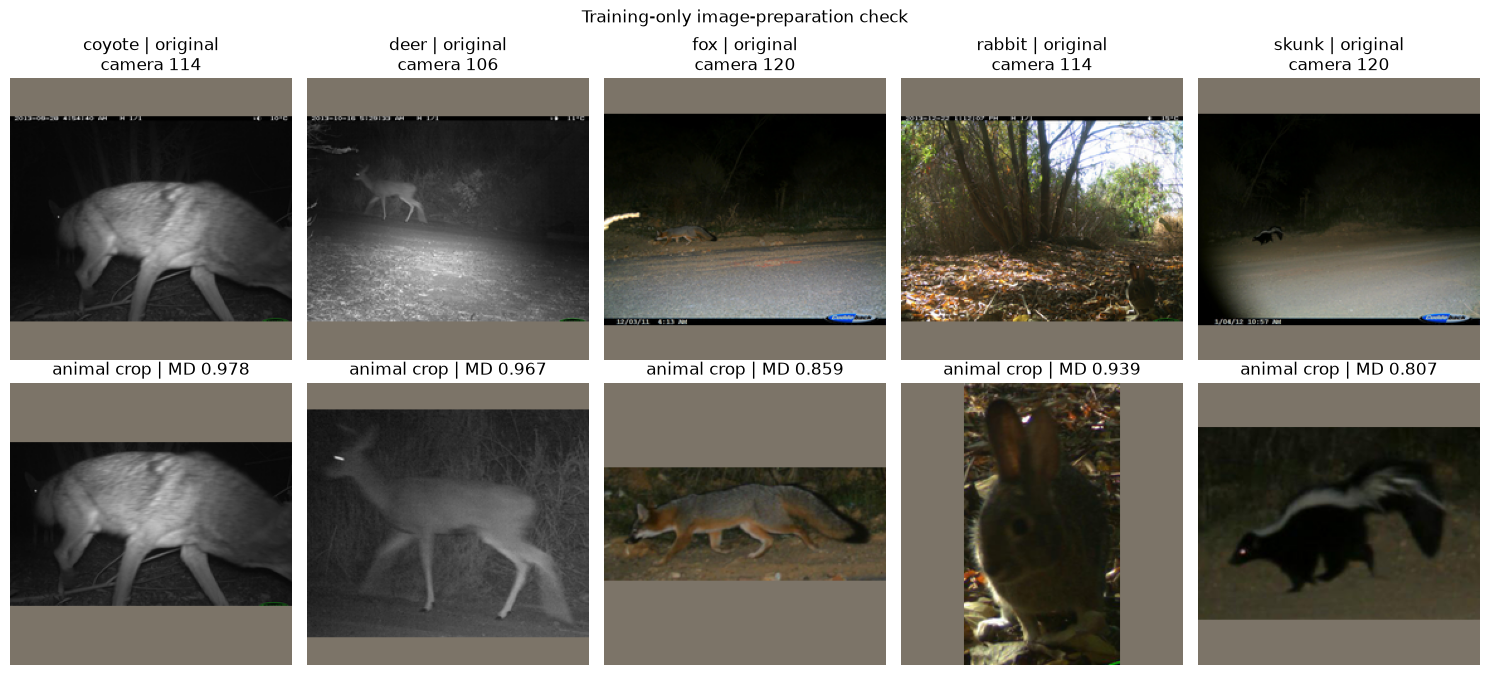

In [30]:
fig, axes = plt.subplots(2, len(CLASSES), figsize=(15, 7))
for col, name in enumerate(CLASSES):
    for ax in axes[:, col]:
        ax.axis("off")
    candidates = verified.loc[verified.split.eq("train") & verified.class_name.eq(name) &
                              verified.image_id.isin(pilot_training_ids)].sort_values("image_id")
    if candidates.empty:
        axes[0, col].set_title(name + " - not prepared")
        continue
    row = candidates.iloc[0]
    preview = PREVIEW / (row.image_id + "_full.png")
    if preview.exists():
        with Image.open(preview) as im:
            axes[0, col].imshow(im)
    axes[0, col].set_title(f"{name} | original\ncamera {row.location}")
    with Image.open(ROOT / row.cache_relative_path) as im:
        axes[1, col].imshow(im)
    decision = plan_lookup[row.image_id]
    caption = (f"animal crop | MD {float(decision['confidence']):.3f}"
               if decision["mode"] == "animal_crop" else "full-frame fallback")
    axes[1, col].set_title(caption)
fig.suptitle("Training-only image-preparation check")
fig.tight_layout()
fig.savefig(DOCS / "training_preprocessing_preview.png", dpi=160, bbox_inches="tight")
plt.show()


### Additional visual inspection — sampled training crops
The sheet `quality_review_template.csv` lists deterministic samples; the contact sheet displays any of those images already prepared. This only illustrates image quality. A person must make the semantic judgements and record them in the review template.

In [31]:
review_available=review_sample.merge(verified[['image_id','cache_relative_path']],
    on='image_id',how='inner',validate='one_to_one')
if review_available.empty:
    print('No manual-review images prepared yet; run pilot/all first.')
else:
    # Paired contact sheets display original full-frame previews AND classifier inputs.
    # Only training events are displayed. All sheets are descriptive, never model test evidence.
    review_available=review_available.sort_values('review_rank').reset_index(drop=True)
    per_sheet=12
    for start in range(0,len(review_available),per_sheet):
        chunk=review_available.iloc[start:start+per_sheet]
        rows=math.ceil(len(chunk)/2)
        fig,axs=plt.subplots(rows,4,figsize=(14,3.4*rows),squeeze=False)
        for ax in axs.flat:ax.axis('off')
        for j,row in enumerate(chunk.itertuples(index=False)):
            r=j//2; col=(j%2)*2
            original=PREVIEW/(row.image_id+'_full.png')
            if original.is_file():
                with Image.open(original) as im:axs[r,col].imshow(im.convert('RGB'))
            axs[r,col].set_title(f'Original | {row.class_name} | camera {row.location}',fontsize=8)
            with Image.open(ROOT/row.cache_relative_path) as im:
                axs[r,col+1].imshow(im.convert('RGB'))
            axs[r,col+1].set_title(f'{row.mode} | {row.image_id[:12]}',fontsize=8)
        fig.tight_layout()
        sheet=DOCS/f'quality_review_contact_sheet_{start//per_sheet+1:02d}.png'
        fig.savefig(sheet,dpi=125,bbox_inches='tight')
        plt.close(fig)
    print('Created',math.ceil(len(review_available)/per_sheet),'paired training-only contact sheets in',DOCS)


Created 6 paired training-only contact sheets in /home/fia/Schreibtisch/wildlife_confidence_project_v2/wildlife_confidence_project_v2/reports/five_categories_camera_balanced_v2


## 15. Optional PyTorch setup and training inputs
`RUN_PILOT = True` attempts a small pilot. The import check is explicit: missing/incompatible PyTorch is logged, not confused with a model result. CUDA is tested with actual forward/backward operations because device detection alone does not establish compatibility with an older GPU. Set `DEVICE_PREFERENCE = "cpu"` if needed.

We pin MobileNetV3-Large ImageNet-1K V2 and EfficientNet-B0 ImageNet-1K V1 weights. Both are ImageNet-pretrained, but their pretraining recipes are not identical. This is a comparison of these pretrained model configurations, not a perfectly isolated causal architecture experiment.

Images are already resized/padded; the Dataset only converts to tensors, applies training-only random horizontal flips, and normalizes with the same ImageNet mean/std. There is no random augmentation in validation or later calibration/policy/test loaders.


In [32]:
RUN_PILOT = False
DEVICE_PREFERENCE = "cpu"  # "auto" or "cpu"
PILOT_BATCH_SIZE = 4
PILOT_STEPS = 8  # First two steps are warm-up; remaining steps estimate steady-state cost.
PILOT_SEED = 123
TORCH_READY = False
pilot_result = {"status": "not_run", "reason": "not attempted"}
try:
    import torch
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
    import torchvision
    from torchvision import models, transforms
    TORCH_READY = True
except Exception as error:
    pilot_result = {"status": "not_run", "reason": f"PyTorch import: {type(error).__name__}: {error}"}
    print(pilot_result["reason"])
    print("Data preparation is independent of PyTorch. Fix the environment before the training stage.")

if TORCH_READY:
    if DEVICE_PREFERENCE not in {"auto", "cpu"}:
        raise ValueError("DEVICE_PREFERENCE must be auto or cpu")
    device = torch.device("cpu")
    device_note = "CPU selected"
    if DEVICE_PREFERENCE == "auto" and torch.cuda.is_available():
        try:
            # Exercise convolution forward/backward, not only a device-name query.
            probe = nn.Conv2d(3, 4, 3).to("cuda")
            probe(torch.randn(2, 3, 16, 16, device="cuda")).sum().backward()
            torch.cuda.synchronize()
            del probe
            device = torch.device("cuda")
            device_note = torch.cuda.get_device_name(0)
        except Exception as error:
            device_note = f"CUDA probe failed; CPU fallback: {type(error).__name__}: {error}"
            torch.cuda.empty_cache()
    if device.type == "cpu":
        torch.set_num_threads(min(4, max(1, torch.get_num_threads())))
    print("PyTorch:", torch.__version__, "torchvision:", torchvision.__version__)
    print("Device:", device, device_note)

    class WildlifeDataset(Dataset):
        def __init__(self, frame, training=False):
            self.frame = frame.reset_index(drop=True).copy()
            operations = [transforms.RandomHorizontalFlip(p=0.5)] if training else []
            operations += [transforms.ToTensor(), transforms.Normalize(
                mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])]
            self.transform = transforms.Compose(operations)

        def __len__(self):
            return len(self.frame)

        def __getitem__(self, index):
            row = self.frame.iloc[index]
            with Image.open(ROOT / row.cache_relative_path) as im:
                tensor = self.transform(im.convert("RGB"))
            return tensor, int(row.label), row.image_id

    def build_model(name, pretrained=True):
        if name == "mobilenet_v3_large":
            weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2 if pretrained else None
            model = models.mobilenet_v3_large(weights=weights)
        elif name == "efficientnet_b0":
            weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
            model = models.efficientnet_b0(weights=weights)
        else:
            raise ValueError(name)
        # Both torchvision models end in a Linear layer inside their classifier.
        old_head = model.classifier[-1]
        model.classifier[-1] = nn.Linear(old_head.in_features, len(CLASSES))
        return model


PyTorch: 2.14.0+cu130 torchvision: 0.29.0+cu130
Device: cpu CPU selected


## 16. Benchmark both models with actual training updates
The pilot fine-tunes the whole network for eight batches, so its timing includes backbone backward passes. It is not the final two-phase training schedule. AdamW (learning rate 0.0001, weight decay 0.0001) is used only as a documented pilot starting point.

We test finite losses/gradients, changed classifier weights, a validation forward pass and checkpoint reload. We do not report pilot accuracy as research evidence. The rough epoch estimate uses measured post-warm-up batch time and the planned training size; it excludes full validation, checkpoint I/O and scheduling overhead. Downloading weights is outside the timed updates.

No calibrated confidence or test prediction is produced here. Final training must start again from the specified pretrained weights, not the pilot checkpoint. The same seed does not give differently shaped architectures identical initial weights.


In [33]:
if not RUN_PILOT:
    pilot_result = {"status": "not_run", "reason": "RUN_PILOT=False"}
elif not TORCH_READY:
    pass  # Preserve the recorded import failure.
elif not pilot_verified or not duplicate_table.empty:
    pilot_result = {"status": "not_run", "reason": "Pilot cache incomplete or cross-split duplicates found"}
else:
    model_records = []
    pilot_train = pilot.loc[pilot.split.eq("train")]
    pilot_val = pilot.loc[pilot.split.eq("validation")]
    (DOCS / "pilot_checkpoints").mkdir(exist_ok=True)
    for model_name in ["mobilenet_v3_large", "efficientnet_b0"]:
        print("Starting technical pilot:", model_name, flush=True)
        model = optimizer = None
        record = {"model": model_name, "status": "failed"}
        try:
            random.seed(PILOT_SEED)
            np.random.seed(PILOT_SEED)
            torch.manual_seed(PILOT_SEED)
            if device.type == "cuda":
                torch.cuda.manual_seed_all(PILOT_SEED)
            generator = torch.Generator().manual_seed(PILOT_SEED)
            train_loader = DataLoader(WildlifeDataset(pilot_train, training=True),
                batch_size=PILOT_BATCH_SIZE, shuffle=True, generator=generator,
                num_workers=0, drop_last=True)
            val_loader = DataLoader(WildlifeDataset(pilot_val, training=False),
                batch_size=PILOT_BATCH_SIZE, shuffle=False, num_workers=0)
            if len(train_loader) < PILOT_STEPS:
                raise ValueError("Not enough pilot batches for the configured timing steps")
            model = build_model(model_name).to(device)
            total_params = sum(p.numel() for p in model.parameters())
            optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
            loss_fn = nn.CrossEntropyLoss()
            initial_head = model.classifier[-1].weight.detach().cpu().clone()
            model.train()
            step_times, losses = [], []
            iterator = iter(train_loader)
            for step in range(PILOT_STEPS):
                if device.type == "cuda":
                    torch.cuda.synchronize()
                t0 = time.perf_counter()
                batch, labels, image_ids = next(iterator)
                batch, labels = batch.to(device), labels.to(device)
                optimizer.zero_grad(set_to_none=True)
                logits = model(batch)
                assert logits.shape == (len(labels), len(CLASSES))
                loss = loss_fn(logits, labels)
                if not torch.isfinite(loss):
                    raise ValueError("Nonfinite training loss")
                loss.backward()
                if not all(torch.isfinite(p.grad).all().item() for p in model.parameters() if p.grad is not None):
                    raise ValueError("Nonfinite gradients")
                optimizer.step()
                if device.type == "cuda":
                    torch.cuda.synchronize()
                step_times.append(time.perf_counter() - t0)
                losses.append(float(loss.detach().cpu()))
            head_change = float((model.classifier[-1].weight.detach().cpu() - initial_head).abs().max())
            if head_change == 0:
                raise ValueError("Classifier weights did not change")
            model.eval()
            val_batch, val_labels, val_ids = next(iter(val_loader))
            with torch.no_grad():
                validation_logits = model(val_batch.to(device)).cpu()
            if not torch.isfinite(validation_logits).all():
                raise ValueError("Nonfinite validation logits")
            checkpoint_path = DOCS / "pilot_checkpoints" / (model_name + "_PILOT_ONLY.pt")
            torch.save({"state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                        "classes": CLASSES, "protocol_sha256": PROTOCOL_SHA,
                        "subset_sha256": SUBSET_SHA, "pilot_only": True}, checkpoint_path)
            # Read only our own just-created checkpoint; no untrusted model file is loaded.
            saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
            model.load_state_dict(saved["state_dict"], strict=True)
            with torch.no_grad():
                restored = model(val_batch.to(device)).cpu()
            if not torch.allclose(validation_logits, restored, rtol=1e-4, atol=1e-5):
                raise ValueError("Checkpoint-reload predictions differ")
            mean_step = float(np.mean(step_times[2:]))
            epoch_minutes = mean_step * math.ceil(int(subset.split.eq("train").sum()) / PILOT_BATCH_SIZE) / 60
            record = {"model": model_name, "status": "passed", "device": str(device),
                      "total_parameters": total_params, "batch_size": PILOT_BATCH_SIZE,
                      "steps": PILOT_STEPS, "seed": PILOT_SEED, "losses": losses,
                      "step_seconds": step_times, "mean_post_warmup_step_seconds": mean_step,
                      "rough_training_epoch_minutes_excluding_validation": epoch_minutes,
                      "classifier_max_weight_change": head_change,
                      "checkpoint_reload_passed": True}
            print(f"Passed. Rough full training epoch: {epoch_minutes:.1f} min (excluding validation).", flush=True)
        except Exception as error:
            record["error"] = f"{type(error).__name__}: {error}"
            print("Pilot failed:", record["error"], flush=True)
        finally:
            del model, optimizer
            if device.type == "cuda":
                torch.cuda.empty_cache()
        model_records.append(record)
    pilot_result = {"status": "passed" if all(r["status"] == "passed" for r in model_records) else "incomplete",
                    "reason": "technical pilot only; not a final accuracy experiment", "models": model_records}
pilot_result.update({"time_utc": utc_now(), "protocol_sha256": PROTOCOL_SHA,
                     "subset_sha256": SUBSET_SHA,
                     "torch_version": str(torch.__version__) if TORCH_READY else None,
                     "torchvision_version": str(torchvision.__version__) if TORCH_READY else None})
atomic_text(DOCS / "pilot_results.json", json_text(pilot_result))
event("pilot_finished", pilot_result)
print("Pilot status:", pilot_result["status"])


Pilot status: not_run


## 17. Generate methods and handoff records from actual outputs
The report draft describes the implemented method and actual execution status. It does not claim skipped pilots or incomplete downloads succeeded. It records predicted-box provenance and limitations explicitly; labels remain dataset-provided image categories, not box-level manual species annotations.


In [34]:
def markdown_table(frame):
    frame=frame.reset_index()
    lines=['| '+' | '.join(map(str,frame.columns))+' |',
           '| '+' | '.join(['---']*len(frame.columns))+' |']
    lines+=['| '+' | '.join(map(str,row))+' |' for row in frame.itertuples(index=False,name=None)]
    return '\n'.join(lines)
bookkeeping=subset[['image_id','class_name','split','location']].merge(
    plan[['image_id','mode','animal_box_count']],on='image_id',validate='one_to_one')
outcomes=pd.crosstab(bookkeeping.split,bookkeeping['mode']).reindex(SPLITS,fill_value=0)
freeze_text(EXP/'planned_detection_outcomes_by_split.csv',outcomes.to_csv())
flow=pd.DataFrame([{'split':split,
    'eligible_events_after_notebook01':len(representatives[representatives.split.eq(split)]),
    'selected_events_after_camera_sampling':len(subset[subset.split.eq(split)]),
    'verified_image_files':len(verified[verified.split.eq(split)])}
    for split in SPLITS])
atomic_text(DOCS/'data_flow.csv',flow.to_csv(index=False))
n_crops=int(plan['mode'].eq('animal_crop').sum())
n_fallback=int(plan['mode'].eq('full_frame_fallback').sum())
n_multiple=int(plan.animal_box_count.gt(1).sum())
max_selected_share=camera_rows.groupby('split').share_of_split.max().round(4)
notes=f"""# Wildlife v2: event-first camera allocation and controlled sampling
Generated: {utc_now()}

## Scope, research validity and class selection
Five known wildlife categories: {CLASSES}; class-index mapping: {CLASS_TO_IDX}. These were pinned **before splitting** in Notebook 01 v2, for continuity with the earlier study, not chosen as the most frequent. All-category event counts and camera diversity are in `data/prepared/category_review.csv`.
The task is closed-set and conditional on the reference category being one of the five. It does not measure detection of empty scenes, unknown animals or end-to-end automation of an unfiltered camera stream. Test-set classifier performance was not consulted for v2 allocation, categories, image selection or cropping.

## Clean events before camera allocation
Notebook 01 v2 removed ambiguous images/sequences, then picked one reproducible frame per event globally. There were {len(ambiguous_sequences)} excluded ambiguous sequence IDs. No event is duplicated or split between cameras. Only then did the optimizer allocate cameras, using metadata counts and category support. This is a custom CCT design, not the CCT20 published benchmark protocol, and it is **not** a random sample of deployment cameras.

### Development eligible event support
{markdown_table(event_support)}

### Development cameras per category
{markdown_table(camera_support)}

## Camera-disjoint v2 samples
Training uses a cap of {TRAIN_PER_CLASS_CAP} events per category and a predeclared {MAX_TRAIN_CAMERA_CLASS_SHARE:.0%} per-camera class budget. Validation/calibration/policy select up to {EVAL_BUDGETS['validation']} events each, permitting at most {MAX_EVAL_CAMERA_SHARE:.0%} of the intended sample from any single camera (at most {int(MAX_EVAL_CAMERA_SHARE*EVAL_BUDGETS['validation'])} per camera). Evaluation cameras are different from training and each other. Test sampling is uniform by eligible event with budget {EVAL_BUDGETS['test']}, and **is not capped by camera**, preserving its selected event mixture. The fitted temperature/policy therefore represent camera-capped development mixtures; they are not automatically valid for natural site frequency mixtures.

### Selected development category counts
{markdown_table(selected_counts)}

### Largest camera shares *after sampling*
{max_selected_share.to_string()}

### Data flow (test values are sampling bookkeeping, not outcome evaluation)
{markdown_table(flow.set_index('split'))}

## Detector, crops and sample integrity
Official LILA precomputed raw MegaDetector v5a.0.0 output: {MD_URL}; archive SHA-256: {MD_SHA}. No local detector inference or repeat-detection elimination. Highest-confidence animal box >= {THRESHOLD:.2f}, expanded {MARGIN:.0%} per side and clipped to the full original resolution; then aspect-preserving resize/pad to {SIDE}x{SIDE} RGB. No qualifying box receives a **full-frame fallback**; technical errors block technical readiness. There are {n_crops} planned crops, {n_fallback} full-frame fallbacks and {n_multiple} images with multiple qualifying animal boxes. Crops and image-level category agreement are NOT automatically verified by the detector or file hash.
Use `quality_review_template.csv` and `quality_review_contact_sheet_*.png` to manually inspect **training only** examples, especially fallbacks and multi-box cases. Manual review completed={quality_completed}; rows explicitly marked with a failure={quality_failures}. This is **separate** from technical readiness; unreviewed samples may have crop-label mismatch. Do not review test samples to tune crop rules.

MegaDetector's historical training sources include Caltech Camera Traps; unseen-camera claims apply to downstream classifier training/fitting, not necessarily the pretrained detector. Compared torchvision backbones use different pretrained ImageNet weights. Any change to crop protocol, category set, camera assignment, or sampling algorithm must be a separately declared experiment tested on new untouched data.

## Run status and provenance
Processed scope: {PROCESS_SCOPE}; verified {len(verified)} of {len(subset)} inputs; **technical** readiness for training={all_ready}; cross-split exact duplicate rows={len(duplicate_table)}. These exact hashes do not guarantee absence of near-duplicates across different cameras. Pilot status={pilot_result['status']}; it is a speed/integrity check, not final model evaluation.
Selected sample SHA-256: {SUBSET_SHA}
Input protocol SHA-256: {PROTOCOL_SHA}
Metadata SHA-256: {prep_record['metadata_sha256']}
Versions: Python {sys.version.split()[0]}, NumPy {np.__version__}, Pandas {pd.__version__}, Pillow {PIL.__version__}.

## References
Dussert et al. (2024), *Being confident in confidence scores: calibration in deep learning models for camera trap image sequences*, https://doi.org/10.1002/rse2.412
Beery, Van Horn & Perona (2018), *Recognition in Terra Incognita*, https://beerys.github.io/CaltechCameraTraps/
Precomputed MDv5a outputs: https://lila.science/megadetector-results-for-camera-trap-datasets/
Guo et al. (2017), *On Calibration of Modern Neural Networks*, https://proceedings.mlr.press/v70/guo17a.html
"""
atomic_text(DOCS/'METHODS_AND_DECISIONS.md',notes)
atomic_text(DOCS/'stage02_run.json',json_text({'time_utc':utc_now(),
    'experiment_id':EXPERIMENT_ID,'protocol_sha256':PROTOCOL_SHA,
    'subset_sha256':SUBSET_SHA,'process_scope':PROCESS_SCOPE,
    'readiness':readiness,'manual_quality_review_complete':quality_completed,
    'manual_quality_failures':quality_failures,'pilot_status':pilot_result['status']}))
atomic_text(DOCS/'REPORT_HANDOFF_CHECKLIST.md',"""# v2 report handoff
- Use METHODS_AND_DECISIONS.md and the actual v2 data support tables.
- Describe five categories as a frozen scope choice made before the camera split.
- Report per-camera and per-class support and maximum camera shares in the selected calibration/policy data.
- Do not equate event-weighted or capped camera samples with a typical future camera.
- Detector boxes are precomputed predictions, not true species boxes; crop/label matching requires manual review.
- Technical image readiness does not certify crop quality.
- The full five-notebook pipeline must be rerun with new v2 experiment paths, checkpoints and temperatures.
- Temperature scaling changes confidence, not class predictions; a 5% policy-set observed error is not a future error guarantee.
- The final test set must not be consulted for model selection or used to revise design.
""")
print('Methods:',DOCS/'METHODS_AND_DECISIONS.md')
print('Technical image readiness:',all_ready,'| manual quality review done:',quality_completed,
      '| optional PyTorch pilot:',pilot_result['status'])

Methods: /home/fia/Schreibtisch/wildlife_confidence_project_v2/wildlife_confidence_project_v2/reports/five_categories_camera_balanced_v2/METHODS_AND_DECISIONS.md
Technical image readiness: True | manual quality review done: False | optional PyTorch pilot: not_run


## Continue with the new v2 experiment
1. Set `PROCESS_SCOPE="pilot"`; inspect the saved training-only crops/quality-review template. Mark observed quality failures rather than silently removing images.
2. Set `PROCESS_SCOPE="all"` and rerun Notebook 02 until **technical readiness** becomes true. The camera split, subset, and detector protocol remain frozen.
3. Reconfigure/retrain notebooks **03–05** to use `wildlife_confidence_project_v2` and `five_categories_camera_balanced_v2`. **Never reuse v1 checkpoints, temperatures, thresholds or test results as if they were v2 outputs.** New results will constitute a new study; evaluate on genuinely untouched cameras and report all failures.